# Bonus B5: How to build the desk as a CrewAI crew

## Goal

We build two specialists whose responsibilities, tools and task context we can inspect. Then we tell a typed answer from a checked decision: a hand-made refund claim passes its schema and fails the task guardrail. Finally we read the live crew's evidence against the database and measure every request both specialists make.

## What you will learn

- How to construct CrewAI's `LLM`, `Agent`, `Task` and `Crew` directly.
- How to give each specialist only the lookups its task needs, and pass customer identity through task context.
- How to read typed task outputs and compare model-written evidence with tool results.
- How to reject a well-typed refund decision with a deterministic task guardrail.
- How to count requests, tokens, seconds and cost across the whole crew.
- When a crew is worth its extra requests, compared with one agent or the specialists of labs 07 and 16.

## Setup

Use this folder's isolated environment; the [README](README.md) has the exact commands. No earlier notebook needs to have run. The common configuration below reads the model and prices from `models.env` and finds the key without printing it.


In [1]:
from pathlib import Path
import asyncio
import json
import os
import re
import sqlite3
import time
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")


model: gpt-6-luna | reasoning effort: none | key found: yes


CrewAI imports storage components even when memory is off. We point its local files at this lab's ignored `outputs/` folder before importing it. Tracing and telemetry are disabled; model requests still go to the configured OpenAI endpoint.


In [2]:
LAB = ROOT / "bonus" / "B5_CrewAI_Crew"
OUTPUTS = LAB / "outputs"
OUTPUTS.mkdir(exist_ok=True)
os.environ["CREWAI_STORAGE_DIR"] = str(OUTPUTS.resolve())
os.environ["CREWAI_TRACING_ENABLED"] = "false"
os.environ["CREWAI_TELEMETRY_DISABLED"] = "true"
os.environ["OTEL_SDK_DISABLED"] = "true"

import json
import sqlite3
from time import perf_counter
from typing import Literal
from importlib.metadata import version
from IPython.display import Image, display
from pydantic import BaseModel
from crewai import Agent, Crew, LLM, Process, Task, TaskOutput
from crewai.tools import tool

print({package: version(package) for package in ["crewai", "openai", "mcp"]})


{'crewai': '1.15.34', 'openai': '2.54.0', 'mcp': '1.30.0'}


## Part A: Establish the facts each specialist can retrieve

A role name tells a model what work to attempt. Tool scope determines which operations our application exposes. We split billing and support so that we can see a real context edge: billing finds the customer and totals, then support uses that customer's ID to retrieve the rep.

Our running question is: **How many invoices does Helena Holý have, what do they add up to, and who is her support rep?** These are historical facts from the public Chinook sample shop, not current customer records. First inspect the customer before using its ID.


In [3]:
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)
row = conn.execute(
    "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
    "WHERE FirstName || ' ' || LastName = ?", ("Helena Holý",)
).fetchone()
print({"customer_id": row[0], "name": row[1], "country": row[2]})


{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}


`customer_id` links this name to invoices and the employee assignment. The connection opens with `mode=ro`, so these tools cannot modify the database. Each SQL placeholder `?` receives an argument separately from the SQL text.

We define three public CrewAI tools with `@tool`. The decorator builds an argument schema from the type hints and description. Each function also appends its arguments and return value to `tool_audit`, so later we can distinguish a model's claims from Python operations that actually happened.


In [4]:
tool_audit = []



The name lookup returns every exact match with its ID and country. The audit preserves the exact result string that reaches the model.


In [5]:
@tool("find_customer")
def find_customer(name: str) -> str:
    """Find a Chinook customer by exact full name and return matching customer IDs."""
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    result = [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]
    text = json.dumps(result, ensure_ascii=False, sort_keys=True)
    tool_audit.append({"tool": "find_customer", "arguments": {"name": name}, "result": text})
    return text



The invoice lookup takes that ID. SQL computes the count and sum, so the model does not need to perform arithmetic over invoice rows.


In [6]:
@tool("get_invoices")
def get_invoices(customer_id: int) -> str:
    """Count a customer's invoices and add their totals in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?",
        (customer_id,)).fetchone()
    text = json.dumps({"customer_id": customer_id, "invoice_count": count, "total": total}, sort_keys=True)
    tool_audit.append({"tool": "get_invoices", "arguments": {"customer_id": customer_id}, "result": text})
    return text



The rep lookup joins customer assignments to employees. A missing customer produces a null rep, which must not become an invented name.


In [7]:
@tool("get_support_rep")
def get_support_rep(customer_id: int) -> str:
    """Name the support rep assigned to a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?",
        (customer_id,)).fetchone()
    text = json.dumps({"customer_id": customer_id, "support_rep": row[0] if row else None}, sort_keys=True)
    tool_audit.append({"tool": "get_support_rep", "arguments": {"customer_id": customer_id}, "result": text})
    return text


Call the decorated objects directly with `.run()`. They return JSON **strings**, which `json.loads` turns back into a list or dictionary. The first lookup returns a list because a search can have no matches; the two ID lookups each return one dictionary. Here we know the exact name has one match, so `[0]` selects it.


In [8]:
customer = json.loads(find_customer.run(name="Helena Holý"))[0]
trusted_invoices = json.loads(get_invoices.run(customer_id=customer["customer_id"]))
trusted_rep = json.loads(get_support_rep.run(customer_id=customer["customer_id"]))
print(customer)
print(trusted_invoices)
print(trusted_rep)
print(find_customer.args_schema.model_json_schema())
tool_audit.clear()


{'country': 'Czech Republic', 'customer_id': 6, 'name': 'Helena Holý'}
{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
{'customer_id': 6, 'support_rep': 'Steve Johnson'}
{'properties': {'name': {'title': 'Name', 'type': 'string'}}, 'required': ['name'], 'title': 'Find_Customer', 'type': 'object'}


Helena is customer 6. The tools report 7 invoices, $49.62 and Steve Johnson. The schema exposes a `name` string; the model cannot submit arbitrary SQL. Clearing the audit excludes these manual demonstrations from the later agent path.

**Checkpoint A.** Explain why `get_support_rep` needs the ID returned by `find_customer`, and why a correct answer without a matching tool audit would not establish a database lookup.


## Part B: Separate output shape from refund policy

Before writing a schema, inspect the kind of answer we want. `evidence` contains two JSON strings copied from the tool results. A string can hold valid JSON, invented text or a false claim; typing it as `str` cannot settle which one it is.

The example request is only a lookup. For a refund request, our **teaching policy** is to recommend human review. This crew can describe a request but has no tool to file one or move money.


In [9]:
example_answer = {
    "customer_id": 6, "customer_name": "Helena Holý",
    "invoice_count": 7, "total": 49.62, "support_rep": "Steve Johnson",
    "recommendation": "answer", "evidence": [
        json.dumps(trusted_invoices, sort_keys=True), json.dumps(trusted_rep, sort_keys=True)]
}
print(json.dumps(example_answer, indent=2, ensure_ascii=False))
print("first evidence field:", json.loads(example_answer["evidence"][0]))


{
  "customer_id": 6,
  "customer_name": "Helena Holý",
  "invoice_count": 7,
  "total": 49.62,
  "support_rep": "Steve Johnson",
  "recommendation": "answer",
  "evidence": [
    "{\"customer_id\": 6, \"invoice_count\": 7, \"total\": 49.62}",
    "{\"customer_id\": 6, \"support_rep\": \"Steve Johnson\"}"
  ]
}
first evidence field: {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}


The invoice specialist's result carries identity, totals and the source string. The support specialist's result repeats the facts and adds the rep, recommendation and evidence. `BaseModel` describes required fields; `Literal` restricts a field to the listed strings. We leave `paid` representable so we can test a dangerous, well-typed claim. Policy belongs in a separate check.


In [10]:
class InvoiceEvidence(BaseModel):
    customer_id: int
    customer_name: str
    invoice_count: int
    total: float
    source_json: str

class DeskAnswer(BaseModel):
    customer_id: int
    customer_name: str
    invoice_count: int
    total: float
    support_rep: str
    recommendation: Literal["answer", "human_review", "paid"]
    evidence: list[str]

example_typed = DeskAnswer.model_validate(example_answer)
print(type(example_typed).__name__, example_typed.recommendation)


DeskAnswer answer


A task guardrail receives `TaskOutput`, CrewAI's container for the raw text and, when requested, a Pydantic object. Returning `(False, feedback)` rejects the result; `(True, result.raw)` accepts its text. We check the recommendation against the application request. Later we check factual accuracy and evidence separately.

`active_request` is local teaching data set before a run. In an application handling concurrent requests, bind policy to each run rather than sharing this mutable dictionary.


In [11]:
active_request = {"customer": "Helena Holý", "refund_requested": False}
guardrail_audit = []

def enforce_refund_policy(result: TaskOutput) -> tuple[bool, str]:
    decision = result.pydantic or DeskAnswer.model_validate_json(result.raw)
    expected = "human_review" if active_request["refund_requested"] else "answer"
    accepted = decision.recommendation == expected
    feedback = "" if accepted else f"recommendation must be {expected}; this crew cannot pay refunds"
    guardrail_audit.append({"accepted": accepted, "recommendation": decision.recommendation,
                            "feedback": feedback})
    return accepted, result.raw if accepted else feedback


Predict both results: will a claim of payment pass the type, and will it pass policy? We construct a hand-made `TaskOutput` to exercise the same function that the real task will use. This is a deterministic fixture, not a model failure.

`model_copy(update=...)` copies an object with changed fields without validating those updates. Here `paid` is already an allowed literal, so the changed object still fits the schema. Use `model_validate` to validate untrusted input.


In [12]:
unsafe = example_typed.model_copy(update={"recommendation": "paid"})
unsafe_output = TaskOutput(description="Hand-made policy fixture", agent="Support specialist",
                          raw=unsafe.model_dump_json(), pydantic=unsafe)
print("typed:", type(unsafe_output.pydantic).__name__)
accepted, feedback = enforce_refund_policy(unsafe_output)
print("accepted:", accepted, "| feedback:", feedback)
assert accepted is False

valid_output = TaskOutput(description="Allowed lookup fixture", agent="Support specialist",
                         raw=example_typed.model_dump_json(), pydantic=example_typed)
assert enforce_refund_policy(valid_output)[0] is True
print("allowed lookup accepted:", True)
guardrail_audit.clear()


typed: DeskAnswer
accepted: False | feedback: recommendation must be answer; this crew cannot pay refunds
allowed lookup accepted: True


The unsafe object has every required field and an allowed literal value. Policy still rejects `paid`, while the ordinary lookup passes. These checks establish both rejection and an allowed path. They do not check evidence, names or totals.

**Checkpoint B.** The fixture is a `DeskAnswer`, `accepted` is `False`, and the feedback says this crew cannot pay refunds. The later live run may pass on its first attempt; a configured retry is not evidence that a repair occurred.


## Part C: Assign tools and context to two tasks

CrewAI exposes four objects: `Agent` holds a role, instructions and capabilities; `Task` owns the deliverable and context dependencies; `Process` chooses coordination; `Crew` runs the assembled tasks. We use direct Python construction so every assignment is visible before a project scaffold hides it.

First use the public `LLM` on a tiny input. `api="responses"` selects OpenAI Responses explicitly. The effort comes from configuration. `max_tokens` here is CrewAI's output limit, which its Responses provider maps to the API's `max_output_tokens`.


In [13]:
demo_llm = LLM(model=f"openai/{MODEL}", api="responses", reasoning_effort=EFFORT,
               max_tokens=400, max_retries=0, stream=False)
print(demo_llm.call("Reply with only READY."))
print(demo_llm.get_token_usage_summary().model_dump())


READY
{'total_tokens': 16, 'prompt_tokens': 11, 'cached_prompt_tokens': 0, 'completion_tokens': 5, 'reasoning_tokens': 0, 'cache_creation_tokens': 0, 'successful_requests': 1}


The tiny call returns text and a usage record. In that record, `prompt_tokens` counts input tokens, `completion_tokens` counts generated tokens and `successful_requests` counts completed model requests; the cache fields describe subsets of input. Part E uses these fields to estimate cost. Now each specialist gets its own `LLM` object, so each usage counter belongs to one specialist. We disable delegation because the task list already assigns both responsibilities. Memory and hosted tracing are unnecessary for this one request.

Billing receives `find_customer` and `get_invoices`; support receives only `get_support_rep`. Naming an agent an approver would not grant it approval authority.


In [14]:
invoice_llm = LLM(model=f"openai/{MODEL}", api="responses", reasoning_effort=EFFORT,
                  max_tokens=700, max_retries=0, stream=False)
support_llm = LLM(model=f"openai/{MODEL}", api="responses", reasoning_effort=EFFORT,
                  max_tokens=700, max_retries=0, stream=False)

billing = Agent(role="Invoice specialist", goal="Find the customer and report grounded invoice totals.",
    backstory="You retrieve facts from the shop database and preserve their source.",
    llm=invoice_llm, tools=[find_customer, get_invoices],
    allow_delegation=False, max_iter=5, cache=False, verbose=False)
support = Agent(role="Support specialist", goal="Find the assigned rep and combine the supplied facts.",
    backstory="You describe support requests and never claim a payment was made.",
    llm=support_llm, tools=[get_support_rep],
    allow_delegation=False, max_iter=4, cache=False, verbose=False)
print([(a.role, [t.name for t in a.tools]) for a in [billing, support]])


[('Invoice specialist', ['find_customer', 'get_invoices']), ('Support specialist', ['get_support_rep'])]


The braces in task text, such as `{customer}`, are kickoff inputs. Billing must carry the name and ID to support. `context=[invoices_task]` declares that dependency explicitly. The invoice `source_json` also travels in that context; support does not get a billing tool.

The final task requests two exact evidence strings. The guardrail checks its recommendation, so we will inspect evidence ourselves rather than assume the instruction was obeyed.


In [15]:
invoices_task = Task(
    description="For {customer}, call find_customer, then get_invoices with the returned ID. "
                "Use only tool results. Return the customer ID, full name, count and total. "
                "Copy the exact JSON string from get_invoices into source_json.",
    expected_output="InvoiceEvidence grounded in the two lookups.",
    agent=billing, output_pydantic=InvoiceEvidence)

support_task = Task(
    description="Answer: How many invoices does {customer} have, what do they add up to, "
                "and who is their support rep? Use the supplied invoice task's customer ID "
                "to call get_support_rep. Copy its name and totals into your answer. "
                "refund_requested={refund_requested}. When True, recommendation must be human_review; "
                "otherwise answer. Never claim a refund was paid. "
                "evidence must contain exactly two strings: the unchanged invoice source_json "
                "and the unchanged get_support_rep JSON result. No extra evidence or commentary.",
    expected_output="DeskAnswer with two source JSON strings and the permitted recommendation.",
    agent=support, context=[invoices_task], output_pydantic=DeskAnswer,
    guardrail=enforce_refund_policy, guardrail_max_retries=1)

crew = Crew(agents=[billing, support], tasks=[invoices_task, support_task],
            process=Process.sequential, memory=False, cache=False, tracing=False, verbose=False)
print("process:", crew.process.value)
print("support context is invoice task:", support_task.context[0] is invoices_task)
print("task output types:", [t.output_pydantic.__name__ for t in crew.tasks])


process: sequential
support context is invoice task: True
task output types: ['InvoiceEvidence', 'DeskAnswer']


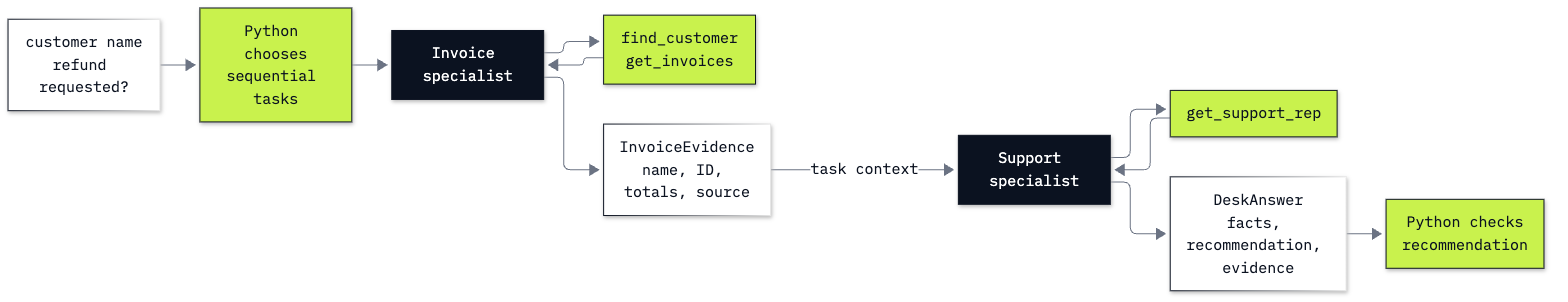

In [16]:
display(Image(filename=str(LAB / "resources" / "labB5_crew.png"), width=760))


Read left to right: the lime process runs tasks in order; each ink model chooses tool calls within its task; Python runs those tools. The context arrow carries the first task's output to the second. There is no manager model in this sequential process.

**Checkpoint C.** Billing has two tools, support has one, and the context identity prints `True`. The two typed outputs are `InvoiceEvidence` then `DeskAnswer`. A role is prompt scaffolding; the tools and policy check are application code.


## Part D: Read the task handoff and model-written evidence

Here a handoff is the typed result one task passes to the next, not a lab 07 handoff of control.

Run the familiar Helena question once before a repeat loop. `await` waits without trying to start another notebook event loop. `kickoff_async` returns a `CrewOutput`; its `tasks_output` list follows task order and its `pydantic` value belongs to the final task.

We snapshot the crew's cumulative usage before and after the kickoff. Subtracting those snapshots counts the whole run, including tool turns, structured-output conversion and any guardrail repair calls. One task need not equal one model request.

⚠️ The next cells make paid calls. The output limits and task iteration caps keep this exercise small. Prices are read from configuration.


In [17]:
tool_audit.clear()
guardrail_audit.clear()
active_request.update(customer="Helena Holý", refund_requested=False)
before = crew.calculate_usage_metrics()
started = perf_counter()
result = await crew.kickoff_async(inputs=active_request.copy())
seconds = perf_counter() - started
usage = crew.calculate_usage_metrics().delta_since(before).model_dump()
invoice_output, support_output = result.tasks_output
answer = result.pydantic
print("handoff type:", type(invoice_output.pydantic).__name__)
print(invoice_output.pydantic.model_dump_json(indent=2))
print("answer type:", type(answer).__name__)
print(answer.model_dump_json(indent=2))


handoff type: InvoiceEvidence
{
  "customer_id": 6,
  "customer_name": "Helena Holý",
  "invoice_count": 7,
  "total": 49.62,
  "source_json": "{\"customer_id\": 6, \"invoice_count\": 7, \"total\": 49.62}"
}
answer type: DeskAnswer
{
  "customer_id": 6,
  "customer_name": "Helena Holý",
  "invoice_count": 7,
  "total": 49.62,
  "support_rep": "Steve Johnson",
  "recommendation": "answer",
  "evidence": [
    "{\"customer_id\": 6, \"invoice_count\": 7, \"total\": 49.62}",
    "{\"customer_id\": 6, \"support_rep\": \"Steve Johnson\"}"
  ]
}


The first object is the evidence support received through task context. Its `source_json` is itself model-written, so even that handoff needs checking. The final answer combines this context with the support tool result. Below we print the Python audit and then read the final `evidence` field beside the two recorded tool outputs.


In [18]:
print("TOOL OPERATIONS")
print(json.dumps(tool_audit, indent=2, ensure_ascii=False))
print("TASK GUARDRAIL")
print(json.dumps(guardrail_audit, indent=2))
print("MODEL-WRITTEN EVIDENCE")
for text in answer.evidence:
    print(text)
print("EXPECTED TOOL EVIDENCE")
expected_evidence = [entry["result"] for entry in tool_audit
                     if entry["tool"] in ["get_invoices", "get_support_rep"]]
for text in expected_evidence:
    print(text)


TOOL OPERATIONS
[
  {
    "tool": "find_customer",
    "arguments": {
      "name": "Helena Holý"
    },
    "result": "[{\"country\": \"Czech Republic\", \"customer_id\": 6, \"name\": \"Helena Holý\"}]"
  },
  {
    "tool": "get_invoices",
    "arguments": {
      "customer_id": 6
    },
    "result": "{\"customer_id\": 6, \"invoice_count\": 7, \"total\": 49.62}"
  },
  {
    "tool": "get_support_rep",
    "arguments": {
      "customer_id": 6
    },
    "result": "{\"customer_id\": 6, \"support_rep\": \"Steve Johnson\"}"
  }
]
TASK GUARDRAIL
[
  {
    "accepted": true,
    "recommendation": "answer",
    "feedback": ""
  }
]
MODEL-WRITTEN EVIDENCE
{"customer_id": 6, "invoice_count": 7, "total": 49.62}
{"customer_id": 6, "support_rep": "Steve Johnson"}
EXPECTED TOOL EVIDENCE
{"customer_id": 6, "invoice_count": 7, "total": 49.62}
{"customer_id": 6, "support_rep": "Steve Johnson"}


Two checks answer different questions. Exact equality tests the copying instruction, including spaces and key order. Parsing both strings and comparing dictionaries allows those presentation differences while still checking the fields. Sorting the normalized strings makes the comparison independent of list order. A parsing failure is recorded as a failed check, not silently accepted.


In [19]:
def same_evidence(generated: list[str], observed: list[str]) -> bool:
    try:
        left = sorted(json.dumps(json.loads(text), sort_keys=True) for text in generated)
        right = sorted(json.dumps(json.loads(text), sort_keys=True) for text in observed)
        return left == right and len(left) == 2
    except (ValueError, TypeError):
        return False

exact_evidence = sorted(answer.evidence) == sorted(expected_evidence)
grounded_evidence = same_evidence(answer.evidence, expected_evidence)
facts_correct = (answer.customer_id == 6 and answer.customer_name == "Helena Holý"
    and answer.invoice_count == trusted_invoices["invoice_count"]
    and answer.total == trusted_invoices["total"] and answer.support_rep == trusted_rep["support_rep"])
print("all answer facts match database:", facts_correct)
print("evidence copied exactly:", exact_evidence)
print("evidence fields match tool results:", grounded_evidence)
print("guardrail evaluations:", len(guardrail_audit), "| accepted:", guardrail_audit[-1]["accepted"])
assert facts_correct
assert guardrail_audit[-1]["accepted"]


all answer facts match database: True
evidence copied exactly: True
evidence fields match tool results: True
guardrail evaluations: 1 | accepted: True


In this saved run, all answer facts match the database. Exact evidence copying is `True`, and the parsed evidence-field comparison is `True`. The guardrail evaluated the live answer once, ending accepted. Both model-written evidence strings match the tool results here; we observed no evidence violation or live policy repair. The hand-made fixture remains the demonstration of rejection.

**Checkpoint D.** The facts are 7, $49.62 and Steve Johnson, and every operation is visible in the audit. The recommendation guardrail does not validate evidence. Even a faithful copy only establishes agreement with these observed results; it does not establish authorization to access a different customer's record.


## Part E: Measure the whole crew and repeat the evidence check

Estimate each successful model response from its usage. Cached input and reported cache writes are subsets of input tokens, so subtract them before charging ordinary input. The calculation includes both specialists; the separate `READY` demonstration has its own counter. CrewAI's native OpenAI provider preserves cached reads but does not expose cache-write tokens in this summary. The estimate therefore omits any unreported write premium; the printed upper bound charges every input token at the configured write rate. Usage also cannot account for a provider failure that never returns billing data.

The main result below is the row to compare with a single desk agent: same Helena question and three lookup capabilities, split across two tasks. Check correctness beside timing so a fast incomplete answer does not look like a win.


In [20]:
def list_cost(usage: dict) -> float:
    prompt = usage["prompt_tokens"]
    cached = usage.get("cached_prompt_tokens", 0)
    written = usage.get("cache_creation_tokens", 0)
    ordinary = prompt - cached - written
    return (ordinary * float(settings["PRICE_INPUT_PER_MILLION"])
        + cached * float(settings["PRICE_CACHED_INPUT_PER_MILLION"])
        + written * float(settings["PRICE_CACHE_WRITE_PER_MILLION"])
        + usage["completion_tokens"] * float(settings["PRICE_OUTPUT_PER_MILLION"])) / 1_000_000

baseline = {"question": "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?",
            "calls": usage["successful_requests"], "input_tokens": usage["prompt_tokens"],
            "output_tokens": usage["completion_tokens"], "seconds": round(seconds, 3),
            "cost_usd": list_cost(usage), "correct": facts_correct,
            "evidence_fields_match": grounded_evidence,
            "tool_path": [entry["tool"] for entry in tool_audit]}
print(json.dumps(usage, indent=2))
print(json.dumps(baseline, indent=2))
print(f"cost upper bound if all input wrote cache: ${(usage['prompt_tokens'] * float(settings['PRICE_CACHE_WRITE_PER_MILLION']) + usage['completion_tokens'] * float(settings['PRICE_OUTPUT_PER_MILLION'])) / 1_000_000:.7f}")


{
  "total_tokens": 3086,
  "prompt_tokens": 2872,
  "cached_prompt_tokens": 0,
  "completion_tokens": 214,
  "reasoning_tokens": 0,
  "cache_creation_tokens": 0,
  "successful_requests": 5
}
{
  "question": "How many invoices does Helena Hol\u00fd have, what do they add up to, and who is her support rep?",
  "calls": 5,
  "input_tokens": 2872,
  "output_tokens": 214,
  "seconds": 12.032,
  "cost_usd": 0.0003942,
  "correct": true,
  "evidence_fields_match": true,
  "tool_path": [
    "find_customer",
    "get_invoices",
    "get_support_rep"
  ]
}
cost upper bound if all input wrote cache: $0.0004660


Now that construction, kickoff and inspection have each run directly, `run_again` packages the same snapshot and kickoff steps. It returns a dictionary with the typed answer, audits, usage and seconds. Ten repetitions measure how often this prompt preserves the evidence; only the request goes to the model, while our answer key stays in Python.

An `async def` function returns a coroutine. `await run_again(...)` runs that coroutine and waits for its result dictionary.


In [21]:
async def run_again(customer_name: str, refund_requested: bool = False) -> dict:
    active_request.update(customer=customer_name, refund_requested=refund_requested)
    tool_audit.clear()
    guardrail_audit.clear()
    before = crew.calculate_usage_metrics()
    started = perf_counter()
    output = await crew.kickoff_async(inputs=active_request.copy())
    elapsed = perf_counter() - started
    delta = crew.calculate_usage_metrics().delta_since(before).model_dump()
    return {"answer": output.pydantic, "task_outputs": output.tasks_output,
            "tools": tool_audit.copy(), "guards": guardrail_audit.copy(),
            "usage": delta, "seconds": elapsed}


`run_again` clears both audits, snapshots usage, runs the crew and returns what it saw; it makes no model call until we await it. The loop below awaits it ten times on the same question. Each printed row gives the run's model requests and the three checks; a run that failed a check would also print its reply and the tool evidence, so we could read what went wrong.

In [22]:
repeats = []
for number in range(1, 11):
    run = await run_again("Helena Holý")
    generated = run["answer"]
    expected = [entry["result"] for entry in run["tools"]
                if entry["tool"] in ["get_invoices", "get_support_rep"]]
    row = {"run": number, "calls": run["usage"]["successful_requests"],
           "facts_correct": generated.customer_id == 6 and generated.customer_name == "Helena Holý"
               and generated.invoice_count == 7 and generated.total == 49.62
               and generated.support_rep == "Steve Johnson",
           "exact_copy": sorted(generated.evidence) == sorted(expected),
           "evidence_fields_match": same_evidence(generated.evidence, expected),
           "guard_evaluations": len(run["guards"])}
    repeats.append({**run, "checks": row})
    print(row)
    if not row["evidence_fields_match"] or not row["facts_correct"] or not row["exact_copy"]:
        print("REPLY TO INSPECT:", generated.model_dump_json())
        print("TOOL EVIDENCE:", expected)


{'run': 1, 'calls': 5, 'facts_correct': True, 'exact_copy': True, 'evidence_fields_match': True, 'guard_evaluations': 1}


{'run': 2, 'calls': 5, 'facts_correct': True, 'exact_copy': True, 'evidence_fields_match': True, 'guard_evaluations': 1}


{'run': 3, 'calls': 5, 'facts_correct': True, 'exact_copy': True, 'evidence_fields_match': True, 'guard_evaluations': 1}


{'run': 4, 'calls': 5, 'facts_correct': True, 'exact_copy': True, 'evidence_fields_match': True, 'guard_evaluations': 1}


{'run': 5, 'calls': 5, 'facts_correct': True, 'exact_copy': True, 'evidence_fields_match': True, 'guard_evaluations': 1}


{'run': 6, 'calls': 5, 'facts_correct': True, 'exact_copy': True, 'evidence_fields_match': True, 'guard_evaluations': 1}


{'run': 7, 'calls': 5, 'facts_correct': True, 'exact_copy': True, 'evidence_fields_match': True, 'guard_evaluations': 1}


{'run': 8, 'calls': 5, 'facts_correct': True, 'exact_copy': True, 'evidence_fields_match': True, 'guard_evaluations': 1}


{'run': 9, 'calls': 5, 'facts_correct': True, 'exact_copy': True, 'evidence_fields_match': True, 'guard_evaluations': 1}


{'run': 10, 'calls': 5, 'facts_correct': True, 'exact_copy': True, 'evidence_fields_match': True, 'guard_evaluations': 1}


The repetitions are finished. Summing their booleans counts passing runs because Python treats `True` as 1 and `False` as 0. The cumulative counters below include the baseline and every repetition; adding the separate demonstration gives the notebook total.


In [23]:
totals = crew.calculate_usage_metrics().model_dump()
demo_usage = demo_llm.get_token_usage_summary().model_dump()
notebook_cost = list_cost(totals) + list_cost(demo_usage)
print("crew requests, including baseline and repeats:", totals["successful_requests"])
print("separate demo requests:", demo_usage["successful_requests"])
print(f"notebook list-price estimate: ${notebook_cost:.6f}")
print("correct facts:", sum(r["checks"]["facts_correct"] for r in repeats), "of", len(repeats))
print("exact evidence copies:", sum(r["checks"]["exact_copy"] for r in repeats), "of", len(repeats))
print("matching evidence fields:", sum(r["checks"]["evidence_fields_match"] for r in repeats), "of", len(repeats))


crew requests, including baseline and repeats: 55
separate demo requests: 1
notebook list-price estimate: $0.004304
correct facts: 10 of 10
exact evidence copies: 10 of 10
matching evidence fields: 10 of 10


Across these ten repetitions, 10 have correct facts, 10 copy evidence exactly and 10 have matching evidence fields. Each used 5 model requests. These are observations under this prompt, not a guarantee for new requests. The first baseline used 5 requests, 2,872 input tokens and 214 output tokens in 12.032 seconds, with a $0.0003942 list-price estimate. That timing describes one run. The summary's notebook total includes the baseline, all ten repetitions and the separate tiny call.

**Checkpoint E.** Read the baseline's `calls` as model requests, not tasks or tool executions. The entire measured path includes structured-output work. Separate tool permissions and an explicit handoff are the benefit we bought. For this fixed lookup, ordinary Python can call all three tools with no model at all. A single agent may need fewer requests: [lab 16](../../16_Agent_Designs/README.md) measures one agent against specialists on the same desk, and [lab 09](../../09_Choose_A_Framework/README.md) sets the frameworks' measured runs side by side, including their different prompts.


## When to use it

The core path splits the desk in lab 07 Part F, where the Agents SDK wires two specialists as tools and as a handoff, and lab 16 measures one agent against specialists on the same questions. CrewAI describes the same split as roles, tasks and a declared context edge. What it gave us here: each specialist saw only its own tools, the result passed from the first task to the second was a typed `InvoiceEvidence` object we could read, and the task guardrail rejected a well-typed `paid` claim before it left the crew. What it cost: two tasks took **5 model requests** per run (tasks are not requests), 2,872 input tokens and about $0.00039 for the Helena baseline. The evidence held in 10 of 10 repeats. Choose a crew when the responsibilities really need different tools, objectives or context and you want each task's deliverable declared; for a fixed lookup like this one, one agent (lab 07) or plain Python is less work. A sequential crew is not a durable approval workflow either: for a pause that must survive a restart, use LangGraph (lab 08, B1), the Agents SDK's `RunState` (B2) or CrewAI's [Flows](https://docs.crewai.com/en/concepts/flows) with their own persistence.

## What you can do now

- Construct and call a CrewAI `LLM`, then assemble two agents and their tasks directly.
- Scope the three database tools and pass customer identity through an explicit context dependency.
- Read each typed task output and compare model-written evidence with observed tool results.
- Reject a schema-valid payment claim using application policy.
- Measure all requests and price the crew before deciding whether the split earns its cost.


## Challenge

1. Reuse this crew for **Puja Srivastava**, setting `refund_requested=True` to represent a made-up duplicate-charge request. Do not add a payment or filing tool. Expect customer 59, 6 invoices, $36.64, Jane Peacock and a `human_review` recommendation.
2. Compare both evidence strings with the actual tool results. Check the tool arguments, final facts, guardrail outcome and complete run usage. Explain why an accepted recommendation still leaves a person's approval outstanding.

Use `run_again`, then inspect its `answer`, `tools`, `guards` and `usage`. A worked run is in [the solution](solved/b5_crewai_crew_solution.ipynb).


## Resources

- [CrewAI agents](https://docs.crewai.com/en/concepts/agents): roles, tools and delegation.
- [Tasks](https://docs.crewai.com/en/concepts/tasks): context, typed outputs and function guardrails.
- [Crews](https://docs.crewai.com/en/concepts/crews): execution and usage metrics.
- [LLMs](https://docs.crewai.com/en/concepts/llms): native OpenAI provider and Responses selection.
- [Tools](https://docs.crewai.com/en/concepts/tools): the public tool decorator and argument schemas.
- [Flows](https://docs.crewai.com/en/concepts/flows): explicit workflow control and state.
- [OpenAI function calling](https://developers.openai.com/api/docs/guides/function-calling): the model proposes calls and application code executes them.
- [Data notes](../../data/README.md): Chinook source and checked fixture facts.

Back to [the bonus lab list](../README.md).
